# Same data, different story

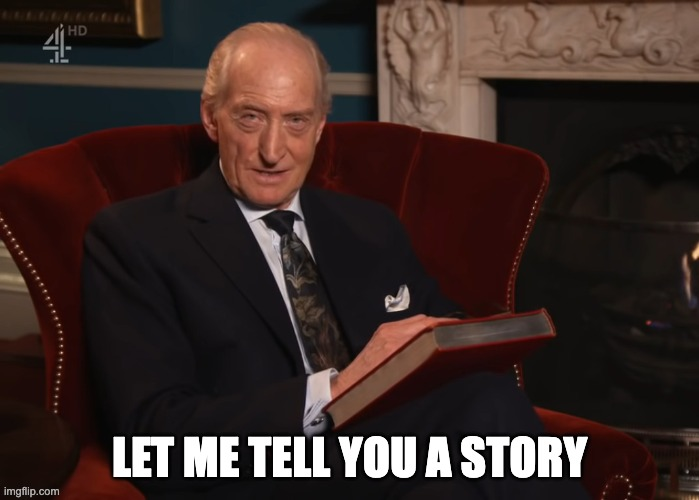

# 1. Houston, we need a kernel
1. Install [Miniconda](https://docs.conda.io/en/latest/miniconda.html)
2. In a terminal, in this folder: `conda env create -f environment.yml`, then `conda activate jacs-plotting`
3. Then: `python -m ipykernel install --user --name jacs-plotting --display-name "JACS plotting"`
4. In [Jupyter](https://jupyter.org/), choose the **JACS plotting** kernel.
5. In [VS Code](https://code.visualstudio.com/), pick the JACS plotting kernel from the kernel selector at the top right of the notebook.

In [ ]:
# Check your setup: run this cell.
import importlib, pathlib

missing = []
for mod in ["numpy", "matplotlib", "matplotlib.colors", "healpy", "corner", "seaborn",
            "astropy", "astropy.io.fits", "astropy.wcs", "astropy.visualization"]:
    try:
        m = importlib.import_module(mod)
        if hasattr(m, "__version__"):
            print(f"{mod:12s} {m.__version__}")
    except ImportError as e:
        missing.append(f"package {mod} ({e})")
for f in ["data/HorseHead.fits", "data/chains_thinned.npz", "data/haslam_nside256.fits"]:
    if not pathlib.Path(f).is_file():
        missing.append(f"data file {f}")

if missing:
    print("⚠️ Not ready yet. Missing:\n  " + "\n  ".join(missing))
    print("Pair up with a neighbour, pip install the package or show this message to the session overlord.")
else:
    print("🎉 All good! Kernel ready, packages found, data in place. Grab your keyboards, it's time to lock in.")

# 2. Choose your fighter

How would you choose a plot and why? 

Check this out: [from-data-to-viz](https://www.data-to-viz.com/)

# 3. Bad Plot, Good Plot

What makes a bad plot and what makes a good plot? Can you spot the plot crimes before you send them off?

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import healpy as hp
import corner
import seaborn as sns
from astropy.io import fits
from astropy.wcs import WCS
from astropy.visualization import simple_norm

rng = np.random.default_rng(42)

---
## a. 1D plot (1D power spectrum)

The [Haslam all-sky map at 408 MHz](https://lambda.gsfc.nasa.gov/product/foreground/fg_2014_haslam_408_info.html) (radio emission, mostly Galactic synchrotron; brightness temperature in K). We measure its angular power spectrum.

(`demo1_power_spectrum_executed.ipynb` goes further, with a cross-spectrum that changes sign.)

In [ ]:
# Data: the Haslam sky map, 408 MHz, publically available on LAMBDA
m = hp.read_map("data/haslam_nside256.fits")
cl = hp.anafast(m, lmax=700)                  # angular power spectrum, K^2
ell = np.arange(cl.size)

In [ ]:
plt.plot(cl)
plt.show()

**Your turn:** You have 4 minutes, how would you improve this?

---
## b. A fit that looks perfect

Toy data: 20 measurements over two decades in $x$, each with a 5% error, fitted with a pure power law.

In [ ]:
rng = np.random.default_rng(42)
x = np.logspace(0, 2, 20)
x0, A, beta, C = 10, 50, -2.0, 0.07
y_true = A * (x / x0) ** beta * np.exp(C * np.log(x / x0) ** 2)   # C > 0: mild curvature
sigma = 0.05 * y_true
y = y_true + rng.normal(0, sigma)

# pure power law = straight line in log space
index, log_norm = np.polyfit(np.log(x), np.log(y), 1, w=y / sigma)
model = np.exp(log_norm) * x ** index
resid = (y - model) / sigma
chi2_dof = np.sum(resid ** 2) / (len(x) - 2)

In [ ]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.errorbar(x, y, yerr=sigma, fmt="o", ms=4, label="data")
ax.plot(x, model, "k-", lw=1, label=rf"power law, index $= {index:.2f}$")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.legend()
plt.show()

**Your turn**: What would you change?

---
## c. 2D power spectrum

A 20° × 20° patch of the same [Haslam map](https://lambda.gsfc.nasa.gov/product/foreground/fg_2014_haslam_408_info.html) near the North Polar Spur, cut out with a flat-sky (gnomonic) projection, and its 2D power spectrum $P(\ell_x, \ell_y)$. (A cylindrical $P(k_\perp, k_\parallel)$, as in 21cm work, needs many frequency channels; a single map only gives the two angular directions.)

**Take-home: read and try.**

In [ ]:
m = hp.read_map("data/haslam_nside256.fits")                # same Haslam map as section a, K

# a 20 x 20 deg patch (flat-sky approximation), near the North Polar Spur
npix_side, reso = 200, 6.0                                   # pixels per side, arcmin per pixel
patch = np.asarray(hp.gnomview(m, rot=(30, 45), xsize=npix_side, reso=reso,
                               return_projected_map=True, no_plot=True), dtype=float)
P2d_raw = np.abs(np.fft.fft2(patch)) ** 2                    # what the FFT gives you straight away

dtheta = np.radians(reso / 60)                               # pixel size in radians
window = np.outer(np.hanning(npix_side), np.hanning(npix_side))   # taper the edges
F = np.fft.fftshift(np.fft.fft2((patch - patch.mean()) * window))
P2d = np.abs(F) ** 2 * dtheta**2 / (npix_side**2 * np.mean(window**2))   # K^2 sr, same units as C_ell
ell_xy = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(npix_side, d=dtheta))
ell_beam = np.sqrt(np.log(2)) / (np.radians(56 / 60) / np.sqrt(8 * np.log(2)))   # ~120: the 56' beam halves the power here

In [ ]:
plt.imshow(P2d_raw, cmap="jet")
plt.show()

**Your turn** : Where is the powr? How do we get it to show up?

---
## d. Histogram binning

Toy data: 300 measurements of a single quantity.

In [ ]:
rng = np.random.default_rng(1)
x_h = np.concatenate([rng.normal(0, 1, 210), rng.normal(3, 1, 90)])   # 70/30 mix, 3 sigma apart

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, n_bins in zip(axes, [8, 25, 80]):
    ax.hist(x_h, bins=n_bins, range=(x_h.min(), x_h.max()))
    ax.set_xlabel("$x$")
axes[0].set_ylabel("Count")
plt.show()

**Your turn:** If binning changes the story, what do we do?

---
## e. Heatmap

Six $H_0$ values from six probes, and the difference between every pair. **These numbers are synthetic** (drawn with a fixed seed), loosely inspired by the real spread; they are not real measurements.

In [ ]:
rng_h = np.random.default_rng(7)
probes = np.array(["CMB", "BAO + BBN", "TRGB", "Cepheids", "Lensing delays", "Masers"])
h0 = np.array([67.5, 68.3, 69.8, 73.0, 72.7, 73.4]) + rng_h.normal(0, 0.3, 6)   # km/s/Mpc, synthetic
h0_err = rng_h.uniform(0.5, 1.5, 6)                                             # 1 sigma, synthetic

D = h0[:, None] - h0[None, :]                              # D[i, j] = H0_i - H0_j
S = np.sqrt(h0_err[:, None] ** 2 + h0_err[None, :] ** 2)    # combined uncertainty
shuffled = rng_h.permutation(6)

In [ ]:
plt.imshow(D[np.ix_(shuffled, shuffled)])
plt.colorbar()
plt.show()

**Your turn:** What can you gather from this heatmap? What would you change?

---
## f. Corner plots and convergence

### Visualising convergence

**Demo:** Same sampler, stopped early versus run to the end. Real Gibbs-sampler output (12 complex parameters, thinned by 10); we plot the real parts of the first four, and cut each run into 4 equal consecutive segments that we treat as chains.

In [ ]:
d = np.load("data/chains_thinned.npz")
thin = int(d["thin"])
run = d["chains"][:, :, :4].reshape(-1, 4)          # the whole run in time order: Re theta_0..theta_3
labels_c = list(d["names"][:4])
n_chains = 4
chain_colours = [f"C{c}" for c in range(n_chains)]  # one colour per chain, used in every plot below

N_EARLY = 5000   # raw samples: the sampler stopped early (= 500 thinned samples)
early = run[: N_EARLY // thin].reshape(n_chains, -1, 4)   # 4 equal consecutive segments
full = run.reshape(n_chains, -1, 4)                         # run to the end: 4 segments of 6,250
BURN_IN = 50     # thinned samples cut from the start of every chain; chain 0 settles after ~50

In [ ]:
def split_rhat(x):
    """Split R-hat for one parameter; x has shape (chain, sample)."""
    n = x.shape[1] // 2
    x = np.concatenate([x[:, :n], x[:, n:2 * n]])       # cut every chain into two halves
    W = x.var(axis=1, ddof=1).mean()                     # within-chain variance
    B = n * x.mean(axis=1).var(ddof=1)                   # between-chain variance
    return np.sqrt(((n - 1) / n * W + B / n) / W)

def plot_traces(ch, title):
    step = np.arange(1, ch.shape[1] + 1)
    fig, axes = plt.subplots(4, 1, sharex=True, figsize=(8, 7))
    for k, ax in enumerate(axes):
        for c in range(n_chains):
            ax.plot(step, ch[c, :, k], color=chain_colours[c], lw=0.6, label=f"chain {c}")
        ax.axvline(BURN_IN, color="k", ls="--", lw=1)
        ax.set_ylabel(labels_c[k])
    axes[0].set_title(title)
    axes[0].legend(ncol=4, fontsize=8, loc="lower right")
    axes[-1].set_xscale("log")                           # log axis so the short burn-in is visible
    axes[-1].set_xlabel(f"Sample in chain (thinned by {thin})")
    plt.show()

def plot_kdes(ch, title):
    kept = ch[:, BURN_IN:, :]
    chain_id = np.repeat([f"chain {c}" for c in range(n_chains)], kept.shape[1])
    fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
    for k, ax in enumerate(axes):
        sns.kdeplot(x=kept[:, :, k].ravel(), hue=chain_id, palette=chain_colours, ax=ax, legend=(k == 0))
        ax.set_xlabel(labels_c[k])
        ax.set_title(rf"split $\hat R$: {split_rhat(ch[:, :, k]):.3f} with burn-in, "
                     f"{split_rhat(kept[:, :, k]):.3f} after cut", fontsize=9)
    fig.suptitle(f"{title} (KDEs after the burn-in cut)", y=1.04)
    plt.show()

The sampler stopped after 5,000 samples, with every sample from all four chains pooled into one corner plot. It looks clean, and the titles quote tidy medians and errors.

---
### Corner plot

Toy posterior samples for four cosmological parameters (a correlated Gaussian).

In [ ]:
names = [r"$\Omega_m$", r"$\sigma_8$", r"$h$", r"$n_s$"]
truth = np.array([0.31, 0.81, 0.674, 0.965])
sig = np.array([0.02, 0.015, 0.01, 0.006])
corr = np.array([[ 1.0, -0.8, -0.6,  0.0],
                 [-0.8,  1.0,  0.4,  0.1],
                 [-0.6,  0.4,  1.0,  0.3],
                 [ 0.0,  0.1,  0.3,  1.0]])
cov = corr * np.outer(sig, sig)
samples = rng.multivariate_normal(truth, cov, size=20000)

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for i in range(4):
    for j in range(4):
        if i == j:
            axes[i, j].hist(samples[:, i], bins=5)
        else:
            axes[i, j].scatter(samples[:, j], samples[:, i])
plt.show()

---
## g. Horsehead nebula image

The Horsehead Nebula, from a UK Schmidt photographic plate (the data is in `data/HorseHead.fits`).

In [ ]:
image = fits.getdata("data/HorseHead.fits").astype(float)
header = fits.getheader("data/HorseHead.fits")
wcs = WCS(header)

In [ ]:
plt.imshow(image, cmap="jet")
plt.show()

**Your turn:** What would you change?

---
## h. Sky map (Haslam 408 MHz)

The Haslam all-sky map at 408 MHz (destriped version, Remazeilles et al. 2015, from [LAMBDA](https://lambda.gsfc.nasa.gov/product/foreground/fg_2014_haslam_408_info.html), at NSIDE 256): radio emission, mostly Galactic synchrotron, as brightness temperature in K.

In [ ]:
sky = hp.read_map("data/haslam_nside256.fits")              # Haslam 408 MHz, brightness temperature in K, Galactic coordinates

In [ ]:
hp.mollview(sky)

**Your turn:** What would you change?

---
## i. Forest plots

Measurements of $H_0$ from different methods. Values are approximate and only for illustration.

In [ ]:
labels = ["Planck CMB", "ACT CMB", "SPT-3G CMB", "BAO + BBN",
          "SH0ES Cepheids", "CCHP TRGB", "H0LiCOW lenses", "Megamasers", "SBF"]
H0 = np.array([67.4, 67.9, 68.8, 67.6, 73.0, 69.8, 73.3, 73.9, 73.3])
H0_err = np.array([0.5, 1.5, 1.5, 1.1, 1.0, 1.7, 1.8, 3.0, 2.5])
early = np.array([True, True, True, True, False, False, False, False, False])

In [ ]:
plt.bar(labels, H0, yerr=H0_err, color=plt.cm.rainbow(np.linspace(0, 1, len(H0))))
plt.xticks(rotation=90)
plt.show()

---
# 4. Time for a makeover

One synthetic figure, restyled four ways: colour, custom palettes, text, and a style file. The section runs on its own: start with the setup cell below.

In [ ]:
# Setup for this section: runs on its own, no data from earlier sections
import shutil
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

plt.style.use("default")                     # start from Matplotlib's defaults

# Synthetic delay power spectrum P(tau), seeded so everyone sees the same figure
rng_mk = np.random.default_rng(2024)
tau = np.linspace(-3000, 3000, 41)           # delay [ns]
P_true = 5e-2 * np.exp(-np.abs(tau) / 250) + 8e-4
P_noise = np.full_like(tau, 2e-4)
cases = {
    "Case I": P_true * (1 + 0.1 * rng_mk.normal(size=tau.size)),
    "Case II": (P_true + 4e-3 * np.exp(-np.abs(tau) / 1500)) * (1 + 0.1 * rng_mk.normal(size=tau.size)),
    "Case III": 0.5 * P_true * (1 + 0.1 * rng_mk.normal(size=tau.size)),
}
offsets = {"Case I": -40, "Case II": 0, "Case III": 40}   # ns, so the error bars don't sit on top of each other


def make_plot(colors=None, linestyles=None, markers=None, hatch="///", legend=True):
    """P(tau) for the three cases.

    Style-free: no colours, fonts, line widths or sizes are hard-coded. Anything not passed
    in comes from rcParams, so a style file changes the look without touching this code.
    """
    fig, ax = plt.subplots()
    handles = {}
    for i, (name, P) in enumerate(cases.items()):
        kw = {}
        if colors is not None:
            kw["color"] = colors[i]
        if linestyles is not None:
            kw["linestyle"] = linestyles[i]
        if markers is not None:
            kw["marker"] = markers[i]
        # one errorbar call per case: colour, linestyle and marker come from the property cycle
        cont = ax.errorbar(tau + offsets[name], P, yerr=0.15 * P, label=name, **kw)
        handles[name] = cont.lines[0]
    ref = mpl.rcParams["axes.edgecolor"]      # reference elements follow the style's axes colour
    ax.plot(tau, P_true, linestyle=":", marker="", color=ref, label="True")
    ax.plot(tau, P_noise, linestyle="-.", marker="", color=ref, label="Noise")
    ax.axvline(300, linestyle=":", color=ref)
    if hatch:
        ax.axvspan(0, 590, hatch=hatch, facecolor="none", edgecolor=ref, label="Excluded")
    else:
        ax.axvspan(0, 590, alpha=0.2, label="Excluded")
    ax.set_yscale("log")
    ax.set_ylim(1e-4, 1e-1)
    ax.set_xlim(-3100, 3100)
    ax.set_xlabel(r"$\tau$ [ns]")
    ax.set_ylabel(r"$P(\tau)$ [arb. units]")
    if legend:
        ax.legend()
    return fig, ax, handles

## Part 1: Colour schemes

Choose the palette type from the type of data, then check the figure still works in grayscale. Colour should never be the only thing that tells two lines apart.

| Your data | Palette type | Examples |
|---|---|---|
| Ordered, one direction (intensity, counts, density) | Sequential | `viridis`, `cividis`, `inferno`, `Blues` |
| Signed, with a meaningful zero (residuals, differences, correlations) | Diverging, centred on zero | `RdBu_r`, `coolwarm`, `PuOr`, with `vmin=-vmax` |
| Unordered categories (instruments, cases, surveys) | Qualitative | [Okabe-Ito](https://jfly.uni-koeln.de/color/), `tab10`, `Set2` |
| Many lines (more than about 6) | Don't rely on colour alone: sample a sequential map if the lines are ordered, otherwise vary linestyle and marker, split into panels, or highlight one and grey the rest | `viridis(np.linspace(0, 1, N))`, small multiples |

In [ ]:
def grayscale_check(fig):
    """Show fig next to its grayscale version (luma = 0.299 R + 0.587 G + 0.114 B)."""
    fig.canvas.draw()
    rgb = np.asarray(fig.canvas.buffer_rgba())[..., :3]
    gray = rgb @ np.array([0.299, 0.587, 0.114])
    fig2, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].imshow(rgb)
    axes[0].set_title("Original")
    axes[1].imshow(gray, cmap="gray", vmin=0, vmax=255)
    axes[1].set_title("Grayscale")
    for a in axes:
        a.set_axis_off()
    plt.show()

In [ ]:
fig, ax, _ = make_plot(colors=["red", "green", "olive"], linestyles=["-", "-", "-"],
                       markers=["o", "o", "o"], hatch=None)
grayscale_check(fig)

**Your turn.** Make the three cases easy to tell apart for everyone, including in grayscale.

In [ ]:
# Your turn: fill in the ____ blanks. Hint: Okabe-Ito colours "#0072B2", "#E69F00", "#009E73"; give each case its own linestyle AND marker; hatch the region (e.g. "///") instead of tinting it.
fig, ax, _ = make_plot(colors=____,
                       linestyles=____,
                       markers=____,
                       hatch=____)
grayscale_check(fig)

**Resources**
- [ColorBrewer](https://colorbrewer2.org/)
- [Matplotlib colormaps reference](https://matplotlib.org/stable/users/explain/colors/colormaps.html)
- [Colorblindly](https://chromewebstore.google.com/detail/colorblindly/floniaahmccleoclneebhhmnjgdfijgg) (browser extension)

## Part 2: Custom palettes

A colormap is a list of colours interpolated in order, so you can build your own from hex codes. Check that its lightness rises steadily; otherwise the image shows features that are not in the data.

In [ ]:
# A small synthetic image: two Gaussian blobs plus a little noise
yy, xx = np.mgrid[-1:1:150j, -1:1:150j]
img = (np.exp(-((xx + 0.35) ** 2 + (yy + 0.2) ** 2) / 0.05)
       + 0.6 * np.exp(-((xx - 0.4) ** 2 + (yy - 0.3) ** 2) / 0.02)
       + 0.03 * np.random.default_rng(7).normal(size=xx.shape))

In [ ]:
makeover = LinearSegmentedColormap.from_list(
    "makeover", ["#1B2021", "#30343F", "#89023E", "#EA638C", "#FFD9DA"])

fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
im = ax.imshow(img, cmap=makeover, origin="lower", extent=[-1, 1, -1, 1])
fig.colorbar(im, ax=ax, label="Intensity [arb. units]")
ax.set_xlabel("x [deg]")
ax.set_ylabel("y [deg]")
grayscale_check(fig)

**Lightness check.** The second and third stops (`#30343F`, `#89023E`) have almost the same lightness (luma about 52 and 49 out of 255; it even dips slightly). So the crimson that marks mid-range values is barely lighter than the background, and in grayscale the smaller blob, which peaks at 0.6, almost disappears. A pretty palette is not automatically a good colormap.

In [ ]:
def strip(ax, colors, title):
    ax.imshow(mpl.colors.to_rgba_array(colors)[None, :, :], aspect="auto")
    ax.set_yticks([])
    ax.set_xticks(range(len(colors)))
    ax.set_title(title, loc="left")

N = 6
fig, axes = plt.subplots(4, 1, figsize=(8, 4.5), layout="constrained")
strip(axes[0], plt.colormaps["tab10"].colors, "tab10: 10 qualitative colours")
strip(axes[1], plt.colormaps["tab20"].colors, "tab20: 10 dark/light pairs")
# N evenly spaced colours from any colormap: call it on np.linspace(0, 1, N)
strip(axes[2], plt.colormaps["viridis"](np.linspace(0, 1, N)), f"{N} colours from viridis")
strip(axes[3], makeover(np.linspace(0, 1, N)), f"{N} colours from makeover")
plt.show()

In [ ]:
# Optional colormap libraries: none is required, and nothing here fails if they are missing
import importlib

examples = {
    "cmasher": 'import cmasher; ax.imshow(img, cmap="cmr.rainforest")',
    "cmocean": 'import cmocean; ax.imshow(img, cmap="cmo.thermal")',
    "colorcet": 'import colorcet; ax.imshow(img, cmap="cet_fire")',
    "cmcrameri": 'import cmcrameri; ax.imshow(img, cmap="cmc.batlow")',
}
for name, example in examples.items():
    try:
        importlib.import_module(name)
        print(f"{name:10s} installed, e.g.  {example}")
    except Exception:
        print(f"{name:10s} not installed: pip install {name}")

**Your turn.** Pick 3 to 5 colours with the [gradient generator](https://eltos.github.io/gradient/) or [Coolors](https://coolors.co/) and paste their hex codes into the cell below.

In [ ]:
# Your turn: fill in the ____ blanks. Hint: paste 3 to 5 hex codes (as strings, with the #) from eltos.github.io/gradient or coolors.co, ordered dark to light.
mine = LinearSegmentedColormap.from_list("mine", ____)

fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
im = ax.imshow(img, cmap=mine, origin="lower", extent=[-1, 1, -1, 1])
fig.colorbar(im, ax=ax, label="Intensity [arb. units]")
grayscale_check(fig)

**A gradient is for continuous data, not for separate line colours.** Neighbouring samples of a gradient look alike, and nobody can match a line to "the fourth shade of pink". For separate lines use a qualitative palette. Sample a gradient only when the lines themselves are ordered (redshift bins, frequencies, time).

**Stretch goal.** Register your map with `mpl.colormaps.register(mine)` so `cmap="mine"` works by name, and try `mine.reversed()`. Or build a diverging map (dark, light, dark, with the light colour in the middle) and show `img - img.mean()` with `vmin=-vmax`.

**Resources**
- [Gradient generator](https://eltos.github.io/gradient/)
- [Coolors](https://coolors.co/)
- [CMasher](https://cmasher.readthedocs.io/)
- [cmocean](https://matplotlib.org/cmocean/)
- [colorcet](https://colorcet.holoviz.org/)

## Part 3: Text

Label the data where it is, instead of in a legend the reader has to decode. Set font sizes once with rcParams, not in every call.

In [ ]:
fig, ax, h = make_plot(legend=False)
ref = mpl.rcParams["axes.edgecolor"]
box = dict(boxstyle="round", facecolor=mpl.rcParams["axes.facecolor"], alpha=0.8)   # keeps text readable over lines

# Direct labels at the right edge, at each line's last value. x is in axes fraction, y in data units
for name, line in h.items():
    ax.annotate(name, xy=(1, cases[name][-3:].mean()), xycoords=("axes fraction", "data"),
                xytext=(4, 0), textcoords="offset points", va="center", color=line.get_color())
ax.annotate("Noise", xy=(1, P_noise[-1]), xycoords=("axes fraction", "data"),
            xytext=(4, 0), textcoords="offset points", va="center", color=ref)

# Text in axes coordinates: (0, 0) is bottom left and (1, 1) top right, whatever the data
ax.text(0.02, 0.97, "Hatched: excluded, 0 to 590 ns", transform=ax.transAxes, va="top", bbox=box)

# Annotations with arrows, in data coordinates
ax.annotate("True model", xy=(-500, 7.6e-3), xytext=(-2900, 1.5e-2),
            arrowprops=dict(arrowstyle="->"), bbox=box)
ax.annotate("300 ns cut", xy=(300, 3e-2), xytext=(1200, 4e-2),
            arrowprops=dict(arrowstyle="->"), bbox=box)
plt.show()

In [ ]:
# Set fonts once for every figure that follows
plt.rcParams.update({
    "font.family": "STIXGeneral",   # a Times-like serif that ships with Matplotlib
    "font.size": 12,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 10,
})
fig, ax, _ = make_plot()
plt.show()

In [ ]:
# Mathtext: Matplotlib's own TeX-like renderer, no LaTeX install needed.
# "stix" makes the maths match the STIX text font set above.
plt.rcParams["mathtext.fontset"] = "stix"

fig, ax, _ = make_plot()
ax.set_ylabel(r"$P(\tau)$ [arb. units]")     # anything between $...$ is typeset as maths
ax.set_title(r"$P(\tau) \propto e^{-|\tau|/\tau_0}$, $\tau_0 = 250$ ns")
plt.show()

In [ ]:
# Real LaTeX, only if it is installed. Otherwise mathtext (above) is already very close.
if shutil.which("latex"):
    try:
        with plt.rc_context({"text.usetex": True, "font.family": "serif"}):
            fig, ax, _ = make_plot()
            ax.set_title(r"Rendered by \LaTeX: $P(\tau) \propto e^{-|\tau|/\tau_0}$")
            fig.canvas.draw()         # render now, so a broken LaTeX install is caught here
        plt.show()
    except Exception as err:
        plt.close("all")
        print(f"LaTeX found but it failed ({type(err).__name__}), using mathtext")
else:
    print("LaTeX not found, using mathtext")

**Your turn.** Set the font sizes once with rcParams, and label Case II on the plot.

In [ ]:
# Your turn: fill in the ____ blanks. Hint: sizes are in points, tick labels usually 1 to 2 pt smaller than axis labels; for the label, read a y-value just above Case II at tau = 1800 ns off the plot above.
plt.rcParams.update({
    "font.size": ____,
    "axes.labelsize": ____,
    "xtick.labelsize": ____,
    "ytick.labelsize": ____,
})
fig, ax, h = make_plot(legend=False)
ax.text(1800, ____, "Case II", color=h["Case II"].get_color(), va="bottom")
plt.show()

**Stretch goal.** Give each direct label a short leader line with `arrowprops=dict(arrowstyle="-")`. Add a secondary x-axis with `ax.secondary_xaxis("top", functions=(f, f_inv))`, e.g. $\tau$ in µs.

**Resources**
- [Matplotlib: text in figures](https://matplotlib.org/stable/users/explain/text/text_intro.html)
- [Matplotlib: mathtext](https://matplotlib.org/stable/users/explain/text/mathtext.html)
- [Matplotlib: text rendering with LaTeX (usetex)](https://matplotlib.org/stable/users/explain/text/usetex.html)

## Part 4: The style file

Put the choices from Parts 1 to 3 into one `.mplstyle` file, and every figure picks them up. `make_plot()` hard-codes nothing, so the same call gets a new look.

**Your turn.** Fill in the blanks, run the cell to write `makeover.mplstyle`, then run the cell after it. Format: `key: value`, one per line, no quotes around values, and hex colours **without** the `#` (in a style file `#` starts a comment).

In [ ]:
%%writefile makeover.mplstyle
# Your turn: fill in the ____ blanks. Hint: the colours are the Okabe-Ito hex codes from Part 1, written as quoted strings without the #.
# makeover.mplstyle   format:  key: value   (no quotes; hex colours WITHOUT the #, because # starts a comment)

# Text
font.size: ____               # base font size in points
axes.labelsize: large           # axis labels one step bigger than font.size
axes.titlesize: large           # titles too

# Lines, markers, hatching
lines.linewidth: ____             # data line width in points
lines.markersize: 5             # marker size in points
hatch.linewidth: ____           # hatch stroke width in points, thinner than the data lines
axes.edgecolor: 444444          # axes frame colour; make_plot also uses it for True, Noise and the hatch

# Colour AND line texture: case i gets colour i, linestyle i and marker i (Okabe-Ito colours)
axes.prop_cycle: cycler(color=[____]) + cycler(linestyle=['-', '--', (0, (3, 1, 1, 1, 1, 1))]) + cycler(marker=['o', 's', '^'])

# Ticks
xtick.direction: ____           # in or out
ytick.direction: in             # same as xtick.direction
xtick.top: True                 # ticks on all four sides
ytick.right: True

# Legend
legend.frameon: ____            # True or False: no box around the legend

In [ ]:
plt.style.use("makeover.mplstyle")
fig, ax, _ = make_plot()          # exactly the same call as in Part 1, no arguments
plt.show()

Styles **layer**: `plt.style.use` only changes the keys in the file, so the STIX fonts from Part 3 are still active above. Start from `"default"` to get only what the file says.

In [ ]:
plt.style.use(["default", "makeover.mplstyle"])
fig, ax, _ = make_plot()
plt.show()

A second, small style can sit on top. `talk.mplstyle` only makes things bigger for slides; later styles win where they overlap.

In [ ]:
%%writefile talk.mplstyle
# talk.mplstyle: bigger everything for slides. Layer it on top of another style.
font.size: 16
lines.linewidth: 3
lines.markersize: 8
figure.figsize: 8, 5.5

In [ ]:
plt.style.use(["makeover.mplstyle", "talk.mplstyle"])
fig, ax, _ = make_plot()
plt.show()

In [ ]:
# Built-in styles: try plt.style.use(["default", "ggplot"]) and re-run make_plot()
print(plt.style.available)

**Don't hard-code colours or fonts in plotting functions.** `make_plot` only says *what* to draw (the data, the labels, which line is the reference). The style decides *how* it looks, so one file restyles every figure in a paper or a talk. Pass a colour in only when it carries meaning, and let reference elements borrow from rcParams (here `axes.edgecolor`).

In [ ]:
plt.style.use("default")          # back to Matplotlib's defaults for the rest of the notebook

**Stretch goal.** Add `savefig.dpi: 300`, `savefig.bbox: tight`, and `axes.grid: True` with `grid.alpha: 0.3`. Then make `paper.mplstyle` with `figure.figsize: 3.4, 2.6` (one journal column) and layer it instead of `talk`. Copy your style into `mpl.get_configdir() + "/stylelib/"` so `plt.style.use("makeover")` works from any folder.

**Resources**
- [Matplotlib: style sheets and rcParams](https://matplotlib.org/stable/users/explain/customizing.html)

In [ ]:
import logging
import numpy as np
import matplotlib.pyplot as plt

# Silence the harmless "font not found" warnings
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

rng = np.random.default_rng(1)
xs = np.linspace(0, 10, 20)
ys = np.sin(xs) + 0.2 * rng.normal(size=xs.size)

with plt.xkcd():
    fig, ax = plt.subplots()
    ax.plot(xs, ys)
    ax.set_title("Secret cell: you found me!")
    ax.set_xlabel("time spent debugging")
    ax.set_ylabel("confidence")
plt.show()

# 5. Seems legit: a cautionary tale

> "The code ran. The plot looks fine. It's must be correct."

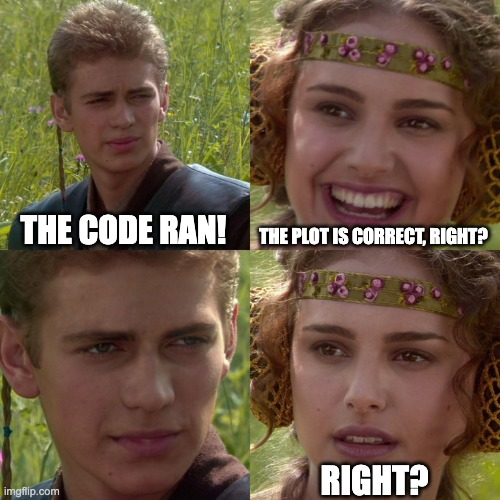

1. **The colourbar that lied:**
2. **More ways it goes wrong:**
3. **Before you trust an AI-made plot:** a checklist

## Demo 1: The colourbar that lied

In [ ]:
# As delivered: three panels, each autoscaled, one colourbar (it only describes the last image)
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
yy, xx = np.mgrid[-1:1:100j, -1:1:100j]
base = np.exp(-((xx + 0.3) ** 2 + yy ** 2) / 0.15) + 0.5 * np.exp(-((xx - 0.45) ** 2 + (yy - 0.35) ** 2) / 0.05)
base /= base.max()
scales = [1, 10, 100]
panels = [s * (base + 0.02 * rng.normal(size=base.shape)) for s in scales]

with plt.style.context("default"):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")
    for ax, img, name in zip(axes, panels, "ABC"):
        im = ax.imshow(img, origin="lower", cmap="viridis", extent=[-1, 1, -1, 1])
        ax.set_title(f"Panel {name}")
        ax.set_xlabel("x [deg]")
    axes[0].set_ylabel("y [deg]")
    fig.colorbar(im, ax=axes, label="Intensity [arb. units]")
    plt.show()

## Demo 2: More ways it goes wrong

### a. Data that isn't yours

In [ ]:
# Data that isn't yours: a tidy scatter that was simulated, not measured
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
x = rng.uniform(0, 10, 40)
y = 2.0 * x + 1.0 + rng.normal(0, 1.0, x.size)        # the "measurements"
fit = np.polyfit(x, y, 1)
with plt.style.context("default"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), sharey=True, layout="constrained")
    for ax in (ax1, ax2):
        ax.errorbar(x, y, yerr=1.0, fmt="o", ms=4)
        ax.plot(np.sort(x), np.polyval(fit, np.sort(x)), label=f"slope = {fit[0]:.2f}")
        ax.set_xlabel("Flux density [mJy]")
        ax.legend(loc="upper left")
    ax1.set_ylabel("Luminosity [arb. units]")
    ax1.set_title("Seems legit")
    ax2.set_title("What's actually going on: simulated, not your data")
    ax2.text(0.97, 0.05, "y = 2.0 x + 1.0 + rng.normal(0, 1.0)", transform=ax2.transAxes,
             ha="right", family="monospace", bbox=dict(boxstyle="round", facecolor="white"))
    plt.show()

### b. Silent data loss

In [ ]:
# Silent data loss: a log axis hides every value <= 0; symlog shows them all
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
x = np.linspace(1, 50, 50)
y = 100 * np.exp(-x / 8) + rng.normal(0, 0.5, x.size)   # decays into noise, so it crosses zero
y[[12, 30]] = 0.0
with plt.style.context("default"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    ax1.plot(x, y, "o", ms=4)
    ax1.set_yscale("log")
    ax1.set_title("Seems legit")
    ax2.plot(x, y, "o", ms=4)
    ax2.set_yscale("symlog", linthresh=1)
    ax2.axhline(0, color="0.5", lw=1)
    ax2.set_title("What's actually going on: symlog, all points")
    for ax in (ax1, ax2):
        ax.set_xlabel("Time [days]")
        ax.set_ylabel("Count rate [counts/s]")
    plt.show()
print(f"points in the data: {y.size}, points visible on the log axis: {np.sum(y > 0)}")

### c. Limits hiding an outlier

In [ ]:
# Limits hiding an outlier: a tight ylim crops the one point that matters
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
x = np.arange(30)
y = 5 + 0.1 * x + rng.normal(0, 0.4, x.size)
y[21] = 19.0                                          # the outlier
with plt.style.context("default"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    for ax in (ax1, ax2):
        ax.plot(x, y, "o-", ms=4)
        ax.set_xlabel("Observation number")
        ax.set_ylabel("Flux [mJy]")
    ax1.set_ylim(4, 9)
    ax1.set_title("Seems legit")
    ax2.annotate("outlier", xy=(21, 19), xytext=(24, 16), arrowprops=dict(arrowstyle="->"))
    ax2.set_title("What's actually going on: full y range")
    plt.show()

### d. Flipped image origin

In [ ]:
# Flipped image origin: data stored with row 0 at the bottom needs origin="lower"
import numpy as np
import matplotlib.pyplot as plt

img = np.zeros((9, 7))            # img[y, x], y increasing upwards
img[1:8, 1] = 1                   # the stem of an "F"
img[7, 1:6] = 1                   # top bar
img[4, 1:5] = 1                   # middle bar
with plt.style.context("default"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4.5), layout="constrained")
    ax1.imshow(img, cmap="gray_r")
    ax1.set_title("Seems legit\norigin='upper' (default): flipped")
    ax2.imshow(img, cmap="gray_r", origin="lower")
    ax2.set_title("What's actually going on\norigin='lower': correct")
    for ax in (ax1, ax2):
        ax.set_xlabel("x [pixel]")
        ax.set_ylabel("y [pixel]")
    plt.show()

### Before you trust an AI-made plot

- Did I ask for the check as well as the plot?
- Did I read the code, not just look at the picture?
- Are the colour limits, axis limits and scales what I intended?
- Does the number of points match my data?
- Is the data mine, and not simulated?
- Did I test with an input where I know the answer?
- Do a few values match the raw numbers?
- Can I explain every line to a reviewer?

**The plot isn't done when it renders. It's done when you've checked it.**

# 6. Bonus cookie for you: interactive plots

Static is for papers. Interactive is for exploring and sharing. Details in the cheat sheet, section 6.
These cells need optional packages and skip themselves if they are missing.
They do not use the style file.

Hover over the outlier.

In [ ]:
# Hover: Plotly Express scatter, coloured by group; hover shows each point's name and values
import numpy as np
try:
    import plotly.express as px
    import pandas as pd
except ImportError:
    print("Optional: pip install plotly nbformat to run this demo. See the cheat sheet, section 6.")
else:
    rng = np.random.default_rng(0)
    n = 200
    centres = {"Survey A": (0.5, 18.0), "Survey B": (1.0, 19.0), "Survey C": (1.5, 18.5)}
    group = rng.choice(list(centres), n)
    colour = np.array([centres[g][0] for g in group]) + rng.normal(0, 0.15, n)
    mag = np.array([centres[g][1] for g in group]) + rng.normal(0, 0.4, n)
    colour[0], mag[0] = 2.8, 15.5                    # the outlier
    df = pd.DataFrame({"name": [f"SRC-{i:03d}" for i in range(n)], "group": group,
                       "colour index": colour, "magnitude": mag})
    fig = px.scatter(df, x="colour index", y="magnitude", color="group", hover_name="name",
                     hover_data={"colour index": ":.2f", "magnitude": ":.2f"}, template="simple_white")
    fig.update_yaxes(autorange="reversed")           # brighter is up, as usual for magnitudes
    fig.show()

Zoom in and pan.

In [ ]:
# Zoom: px.imshow of a synthetic image (a few Gaussian blobs plus noise)
import numpy as np
try:
    import plotly.express as px
except ImportError:
    print("Optional: pip install plotly nbformat to run this demo. See the cheat sheet, section 6.")
else:
    rng = np.random.default_rng(0)
    yy, xx = np.mgrid[-1:1:200j, -1:1:200j]
    img = 0.05 * rng.normal(size=xx.shape)
    for x0, y0, w, a in [(-0.4, -0.2, 0.05, 1.0), (0.3, 0.4, 0.01, 0.8), (0.5, -0.5, 0.002, 1.5), (-0.6, 0.6, 0.02, 0.5)]:
        img += a * np.exp(-((xx - x0) ** 2 + (yy - y0) ** 2) / w)
    fig = px.imshow(img, origin="lower", color_continuous_scale="viridis",
                    labels={"x": "x [pixel]", "y": "y [pixel]", "color": "Intensity"})
    fig.show()

The same stretch idea as the sky map, live.

In [ ]:
# Slider: ipywidgets interact re-draws an arcsinh stretch, np.arcsinh(image / s), as you move s
import numpy as np
import matplotlib.pyplot as plt
try:
    from ipywidgets import interact, FloatSlider
except ImportError:
    print("Optional: pip install ipywidgets to run this demo. See the cheat sheet, section 6.")
else:
    rng = np.random.default_rng(0)
    yy, xx = np.mgrid[-1:1:150j, -1:1:150j]
    image = (5000 * np.exp(-(xx ** 2 + yy ** 2) / 0.003)                      # bright, compact source
             + 40 * np.exp(-((xx + 0.35) ** 2 + (yy - 0.25) ** 2) / 0.12)     # faint, extended emission
             + rng.normal(0, 2, xx.shape))

    def show(s):
        fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
        im = ax.imshow(np.arcsinh(image / s), origin="lower", cmap="gray", extent=[-1, 1, -1, 1])
        fig.colorbar(im, ax=ax, label="asinh(I / s)")
        ax.set_title(f"s = {s:g}")
        plt.show()

    interact(show, s=FloatSlider(min=10, max=3000, step=10, value=300, description="s"))

When static is better: papers, theses, and anything printed. Make the static version with your style file.

# Oh what's this? 

In [ ]:
from top_secret import secret_func

secret_func()